# Circulytics Score Calculator (Unofficial)
This notebook calculates a company's Circulytics score using ipywidgets. It implements the Ellen MacArthur Foundation's [archived methodology](https://www.circulytics.com/).


In [1]:
import math, json, numpy as np, pandas as pd
import ipywidgets as w
from ipywidgets import interact_manual, FloatText, VBox, Output, Label
from IPython.display import display, Markdown

from indicator_list import *

define parameters and functions to be used in calculation

In [2]:
layout = w.Layout(width='1000px')

industry_classes = [
    # Consumer / End Products (CP)
    "CP.1 Consumer/end products: Apparel, textiles, footwear",
    "CP.2 Consumer/end products: Building products and household goods",
    "CP.3 Consumer/end products: E-commerce and retail",
    "CP.4 Consumer/end products: Electronic appliances",
    "CP.5 Consumer/end products: Food and beverage",
    "CP.6 Consumer/end products: Health and personal care",
    "CP.7 Consumer/end products: Industrial machinery",
    "CP.8 Consumer/end products: Leisure products, toys",
    "CP.9 Consumer/end products: Transportation products",
    "CP.10 Consumer/end products: Other consumer/end products",

    # Intermediate Products (IP)
    "IP.1 Intermediate products: Construction materials not specified elsewhere",
    "IP.2 Intermediate products: Metal products and parts",
    "IP.3 Intermediate products: Packaging",
    "IP.4 Intermediate products: Plastic products and parts",
    "IP.5 Intermediate products: Wood, paper, and other natural fiber products",
    "IP.6 Intermediate products: Other intermediate products",

    # Upstream Processing (UP)
    "UP.1 Upstream processing: Cement manufacturing",
    "UP.2 Upstream processing: Chemicals manufacturing (incl. intermediate and end product chemicals)",
    "UP.3 Upstream processing: Mining and metals",
    "UP.4 Upstream processing: Up and mid-stream oil and gas",
    "UP.5 Upstream processing: Wood, pulp, natural fibers processing",
    "UP.6 Upstream processing: Other upstream materials processing",

    # Agriculture, Forestry, Fishing (AF)
    "AF.1 Agriculture for food or fiber",
    "AF.2 Animal husbandry, aquaculture, fishing",
    "AF.3 Forestry and silviculture",
    "AF.4 Other agriculture, forestry, fishing",

    # Infrastructure (IN)
    "IN.1 Construction and building: residential, industrial and civil engineering",
    "IN.2 Real estate management and property development",
    "IN.3 Water utilities and waste water management",
    "IN.4 Waste management and materials recirculation",
    "IN.5 Other infrastructure",

    # Transportation (TR)
    "TR.1 Transportation of goods: freight, logistics, storage",
    "TR.2 Transportation of people: airlines, rail, taxis services, cruise lines, marine transport, etc.",
    "TR.3 Other transportation",

    # Energy (EN)
    "EN.1 Downstream oil and gas for energy",
    "EN.2 Electricity generation",
    "EN.3 Energy grid and other infrastructure",
    "EN.4 Energy retail and other services",
    "EN.5 Energy storage",
    "EN.6 Other energy",

    # Finance and Insurance (FI)
    "FI.1 Asset management and ownership",
    "FI.2 Commercial and retail banking",
    "FI.3 Insurance",
    "FI.4 Investment banking",
    "FI.5 Other finance and insurance",

    # Services (SE)
    "SE.1 Education and research",
    "SE.2 Healthcare and social work services",
    "SE.3 Hospitality and leisure facilities",
    "SE.4 Media and entertainment",
    "SE.5 Marketing, communications, PR agencies",
    "SE.6 Professional and commercial services not specified elsewhere",
    "SE.7 Non-profit organisations (incl. philanthropic funders and NGOs not specified elsewhere)",
    "SE.8 Repair, refurbishing, remanufacturing services",
    "SE.9 Telecommunications, software and IT services",
    "SE.10 Other services",

    # Institutions, Governments and Cities (IGC)
    "IGC.1 International and multilateral organisations",
    "IGC.2 European institutions",
    "IGC.3 National government",
    "IGC.4 Subnational government",
    "IGC.5 City government",
    "IGC.6 Local government",
    "IGC.7 Other policy-oriented organisations (incl. policy-oriented NGOs, think tanks and research institutes)"
]
finance_industry_classes = [
    "FI.1 Asset management and ownership",
    "FI.2 Commercial and retail banking",
    "FI.3 Insurance",
    "FI.4 Investment banking",
    "FI.5 Other finance and insurance",
]

In [17]:
clip_0_to_100 = lambda x: max(0.0, min(100.0, float(x)))
clip_0_to_1 = lambda x: max(0.0, min(1.0, float(x)))

def to_letter_score(score):
    s = clip_0_to_100(score)
    bands = [
        (88.89, 100.0, 'A'), (77.78, 88.89, 'A-'), (66.67, 77.78, 'B'), (55.56, 66.67, 'B-'),
        (44.44, 55.56, 'C'), (33.33, 44.44, 'C-'), (22.22, 33.33, 'D'), (11.11, 22.22, 'D-'), (0.0, 11.11, 'E')
    ]
    for lo, hi, letter in bands:
        if s >= lo and s <= hi:
            return letter
    return 'E'

ENABLER_THEME_WEIGHTS = {1:0.30,2:0.20,3:0.15,4:0.15,5:0.20}
THEME_5_INDICATOR_WEIGHTS = {'5a':0.30,'5b':0.30,'5c':0.15,'5d':0.15,'5e':0.10}

# Theme 8 weighting information
ASSET_AVG_MASS = {
    'IT equipment': 0.01,              # t/item
    'Textiles': 0.001,                 # t/item
    'Furniture': 0.05,                 # t/item
    'Buildings': 2.5,                  # t/m2
    'Heavy machinery': 50.0,           # t/item
    'Mid-weight machinery': 25.0,      # t/item
    'Light machinery': 0.5,            # t/item
    'Heavy transport': 1000.0,         # t/item
    'Mid-weight transport': 500.0,     # t/item
    'Light transport': 5.0,            # t/item
    'Warehousing equipment': 0.05      # t/item
}
ASSET_GROUPS = list(ASSET_AVG_MASS.keys())

def asset_row_widgets(label):
    asset_label = w.Label(value=f"{label} mass (t, FY)", layout=w.Layout(width='200px'), style = {'description_width': 'initial'})
    mass_label = w.Label(value = f"{ASSET_AVG_MASS[label]} t/item" if label != "Buildings" else f"{ASSET_AVG_MASS[label]} t/m2", layout=w.Layout(width='120px'))
    mass_estimate = w.FloatText(value=0.0, disabled=False, layout=w.Layout(width='200px'),style = {'description_width': 'initial'})
    
    return {
        'name': label,
        'mass_widget': mass_estimate,
        'mass_box': w.HBox([asset_label, mass_label, mass_estimate]),
        'applicable_and_mass_not_available': w.Checkbox(value=False, layout=w.Layout(width='200px')),
        'not_applicable': w.Checkbox(value=False, layout=w.Layout(width='150px')),
    }

asset_widgets_procured = [asset_row_widgets(a) for a in ASSET_GROUPS]
asset_widgets_owned = [asset_row_widgets(a) for a in ASSET_GROUPS]

header_row = w.HBox([
    w.Label(value='Asset Category', layout=w.Layout(width='200px')),
    w.Label(value='Average mass', layout=w.Layout(width='120px')),
    w.Label(value='Mass estimate (metric tonnes)', layout=w.Layout(width='200px')),
    w.Label(value='Applicable and mass estimate not available', layout=w.Layout(width='275px')),
    w.Label(value='Not applicable', layout=w.Layout(width='150px')),
])

prompt_0q_part1 = w.HTML('<h3>0q. Part 1. For each plant, property, and equipment assets category that your company has procured (either to own or to lease) in the financial year stated at the beginning of the assessment, what is the total mass (metric tonnes) of each category?</h3><p>If you do not have the total mass, but know the number of items in each asset category, use the average mass in the table below to estimate the total mass for each asset category.</p>')
asset_rows_procured = [prompt_0q_part1, header_row]

prompt_0r_part1 = w.HTML('<h3>0r. Part 1. For all the plant, property and equipment assets that are procured during or before the financial year (FY) stated at the beginning of the assessment (and are owned or leased by your company at any point during the FY), what is the total mass (metric tonnes) of each category?</h3><p>If you do not have the total mass, but know the number of items in each asset category, you can use the average mass in the table below to estimate the total mass for each asset category.</p>')
asset_rows_owned = [prompt_0r_part1, header_row]

for r in asset_widgets_procured:
    asset_rows_procured.append(w.HBox([r['mass_box'], r['applicable_and_mass_not_available'], r['not_applicable']]))
for r in asset_widgets_owned:
    asset_rows_owned.append(w.HBox([r['mass_box'], r['applicable_and_mass_not_available'], r['not_applicable']]))
ui_8_procured = w.VBox(asset_rows_procured)
ui_8_owned = w.VBox(asset_rows_owned)

prompt_0q_part2 = w.HTML('<h3>0q. Part 2. For each plant, property, and equipment asset category procured in the financial year stated at the beginning of the assessment: Select asset categories that cover a minimum of 80% of the mass estimates provided in 0q. Part 1.</h3>')
subprompt_0q_part2 = w.HTML('<h4>Your selections here will be used to inform the relevance and weighting of asset groups in indicator 8b.</h4>')
header = w.Label(value='Asset group', layout=w.Layout(width='200px'))
asset_selection_table_0q = w.VBox([prompt_0q_part2,subprompt_0q_part2, header] + [w.Checkbox(value=False, description=a, indent=False) for a in ASSET_GROUPS])

prompt_0r_part2 = w.HTML('<h3>0r. Part 2. For each plant, property and equipment asset category procured during or before the financial year (FY) stated at the beginning of the assessment (and owned or leased at any point during the FY). Select asset categories that cover a minimum of 80% of the mass estimates provided in 0r. Part 1.</h3>')
subprompt_0r_part2 = w.HTML('<h4>Your selections here will be used to inform the relevance and weighting of asset groups in indicator 8b.</h4>')
header = w.Label(value='Asset group', layout=w.Layout(width='200px'))
asset_selection_table_0r = w.VBox([prompt_0r_part2, subprompt_0r_part2, header] + [w.Checkbox(value=False, description=a, indent=False) for a in ASSET_GROUPS])

def compute_outcomes_theme_weights(company):
    weights = {6:0.0,7:0.0,8:0.0,9:0.0,10:0.0,11:0.0}
    ind = company['industry_type']
    services = bool(company.get('services_sold',False))
    mats = bool(company.get('material_flows',False))
    own = bool(company.get('ownership',False))
    water = bool(company.get('water_intensive',False))
    energy_prod = bool(company.get('energy_producer',False))
    if ind in finance_industry_classes:
        weights[11] = 0.7
        if water: weights[8]=0.1; weights[10]=0.1; weights[9]=0.1
        else: weights[8]=0.15; weights[10]=0.15
        return weights
    if energy_prod:
        weights[10] = 0.7
        if water: weights[8]=0.1; weights[9]=0.1; weights[9]=0.1
        else: weights[8]=0.15; weights[10]=0.15
        return weights
    if mats and not services:
        weights[6] = 0.7
        if water: weights[8]=0.1; weights[10]=0.1; weights[9]=0.1
        else: weights[8]=0.15; weights[10]=0.15
        return weights
    if services and not mats:
        weights[7] = 0.7
        if water: weights[8]=0.1; weights[10]=0.1; weights[9]=0.1
        else: weights[8]=0.15; weights[10]=0.15
        return weights
    if services and mats:
        if own: weights[6]=0.65; weights[7]=0.05
        else: weights[6]=0.05; weights[7]=0.65
        if water: weights[8]=0.1; weights[10]=0.1; weights[9]=0.1
        else: weights[8]=0.15; weights[10]=0.15
        return weights
    raise AssertionError("Company must either be a financial institution, have material flows, or have services.")

def score_linear_choice(idx, options):
    if idx is None or idx < 1 or idx > len(options): return 0.0
    return clip_0_to_100(options[idx-1])

def score_sum_checks(percent_list):
    return clip_0_to_100(sum(percent_list))

def theme6_indicator_weights(masses, theme_indicator_widgets):
    denoms = {'6a':masses.get('MIN',0.0),'6b':masses.get('MWASTE1',0.0),'6c':masses.get('MWASTE2',0.0),'6d':masses.get('MPROD1',0.0)+masses.get('MPROD2',0.0),'6e':masses.get('MPROD1',0.0)+masses.get('MPROD2',0.0)+masses.get('MWASTE1',0.0)+masses.get('MWASTE2',0.0),'6f_part1':masses.get('MPROD2',0.0), '6f_part2':(theme_indicator_widgets[6]['6f_part1']['sliders'][0].value/100)*masses.get('MPROD2',0.0)}
    total = sum(denoms.values())
    return {k:(v/total) if total>0 else 0.0 for k,v in denoms.items()}

def theme9_indicator_weights(demand_ml, outflow_ml):
    total = demand_ml + outflow_ml
    if total<=0: return {'9a':0.0,'9b':0.0,'9c':0.0,'9d':0.0}
    d = demand_ml/total; o = outflow_ml/total
    return {'9a':d*0.5,'9b':d*0.5,'9c':o*0.5,'9d':o*0.5}

def theme10_indicator_weights(use_mwh, prod_mwh, is_producer):
    if not is_producer: return {'10a':1.0,'10b':0.0}
    total = use_mwh + prod_mwh
    if total<=0: return {'10a':0.5,'10b':0.5}
    return {'10a':use_mwh/total,'10b':prod_mwh/total}

def weighted_average(items):
    wsum = sum(w for _,w in items)
    if wsum<=0: return 0.0
    return sum(s*w for s,w in items)/wsum

def build_dropdown_block(indicator_code: str, prompt: str, options: list[str], scores: list[float], subprompt: str | None = None, bonus_checkbox: dict | None = None) -> w.VBox:
    """
    Render a theme item like Theme 1: prompt heading + explicit options + dropdown.
    The dropdown stores a normalized 0..1 value by mapping the option index
    against the number of options, consistent with Theme 1 style.
    """
    prompt_h3 = w.HTML(f"<h3>{indicator_code}. {prompt}</h3>")
    prompts = [prompt_h3]
    if subprompt is not None:
        subprompt_w = w.Label(value=subprompt)
        prompts.append(subprompt_w)
    
    options_list = [w.Label(value=f"{i+1}: {opt}") for i, opt in enumerate(options)]
    if len(options) > 1:
        dropdown = w.Dropdown(
            options=[(f"Option {i+1}", scores[i]) for i in range(len(options))],
            description=f"Select Answer for {indicator_code}",
            style={'description_width': 'initial'}
        )
    else:
        dropdown = w.Dropdown(options=[("Option 1", 1.0)], description=f"Select Answer for {indicator_code}")
    items_for_box = prompts + options_list + [dropdown]
    ui = {'dropdown': dropdown}
    if bonus_checkbox is not None:
        cb = w.Checkbox(value=False, description=bonus_checkbox.get('label',''), indent=False)
        items_for_box.append(cb)
        ui['bonus_checkbox'] = cb
    return w.VBox(items_for_box), ui

def build_checkbox_block(indicator_code: str, prompt: str, options: list[str], subprompt: str | None = None) -> w.VBox:
    """
    Render prompt heading + checkboxes for 'select all that apply' pattern,
    consistent with Theme 1 (e.g., 1e; 1d functions block).
    """
    prompt_h3 = w.HTML(f"<h3>{indicator_code}. {prompt}</h3>")
    prompts = [prompt_h3]
    if subprompt is not None:
        subprompt_w = w.Label(value=subprompt)
        prompts.append(subprompt_w)
    cbs = [w.Checkbox(value=False, description=opt, indent=False) for opt in options]
    return w.VBox(prompts + cbs), cbs

def build_grouped_checkbox_block(indicator_code: str, prompt: str, group_labels: list[str],group_sublabels: list[str], group_options: list[list[str]], subprompt: str | None = None) -> w.VBox:
    """
    Render prompt heading + grouped checkboxes for 'select all that apply' pattern
    """
    prompt_h3 = w.HTML(f"<h3>{indicator_code}. {prompt}</h3>")
    prompts = [prompt_h3]
    if subprompt is not None:
        subprompt_w = w.Label(value=subprompt)
        prompts.append(subprompt_w)
    all_cbs = []
    for glabel, gsublabel, goptions in zip(group_labels, group_sublabels, group_options):
        group_header = w.HTML(f"<h4>{glabel}</h4>")
        prompts.append(group_header)
        sublabel_w = w.Label(value=gsublabel)
        prompts.append(sublabel_w)
        cbs = [w.Checkbox(value=False, description=opt, indent=False) for opt in goptions]
        prompts.extend(cbs)
        all_cbs.append(cbs)
    return w.VBox(prompts), all_cbs

def build_both_block(indicator_code: str, prompt: str, dropdown_options: list[str], dropdown_scores: list[float], checkbox_label: str, checkbox_options: list[str], subprompt: str | None = None) -> w.VBox:
    """
    Render prompt heading + dropdown options + checkbox sublist,
    matching Theme 1 'both' pattern (e.g., 1d).
    """
    prompt_h3 = w.HTML(f"<h3>{indicator_code}. {prompt}</h3>")
    prompts = [prompt_h3]
    if subprompt is not None:
        subprompt_w = w.Label(value=subprompt)
        prompts.append(subprompt_w)
    dd_opts_visible = [w.Label(value=f"{i+1}: {opt}") for i, opt in enumerate(dropdown_options)]
    dropdown = w.Dropdown(
        options=[(f"Option {i+1}", dropdown_scores[i]) for i in range(len(dropdown_options))],
        description=f"Select Answer for {indicator_code}",
        style={'description_width': 'initial'}
    )
    cb_prompt = w.HTML(f"<h4>{checkbox_label}</h4>")
    cbs = [w.Checkbox(value=False, description=opt, indent=False) for opt in checkbox_options]
    return w.VBox(prompts + dd_opts_visible + [dropdown, cb_prompt] + cbs), (dropdown, cbs)

def build_info_input_block(title_h3: str, sublabel: str, widget: w.Widget) -> w.VBox:
    """
    Wrap any single numeric or text input with a Theme-1-like heading and sublabel.
    Use for themes 6..11 'Information for weighting' entries to keep visual consistency.
    """
    h3 = w.HTML(f"<h3>{title_h3}</h3>")
    sub = w.Label(value=sublabel)
    return w.VBox([h3, sub, widget])

def build_slider_block(indicator_code: str, prompt: str, min_val: float = 0, max_val: float = 100, step: float = 1, subprompt: str | None = None) -> w.VBox:
    """
    Creates a UI block for a single slider input with a heading and description.
    
    Parameters:
    - indicator_code: str, e.g., "6b" or "10a"
    - prompt: str, descriptive text for the indicator
    - min_val: float, minimum slider value (default 0)
    - max_val: float, maximum slider value (default 100)
    - step: float, step size for slider (default 1)
    
    Returns:
    - ipywidgets.VBox containing the heading and slider widget
    """
    heading = [w.HTML(f"<h3>{indicator_code}. {prompt}</h3>")]
    if subprompt is not None:
        subprompt_w = w.Label(value=subprompt)
        heading.append(subprompt_w)
    slider = w.FloatSlider(
        value=0,
        min=min_val,
        max=max_val,
        step=step,
        description=f"{indicator_code} (%)",
        style={'description_width': 'initial'},
        layout=w.Layout(width='500px')
    )
    return w.VBox(heading+[slider]), slider

def build_composite_slider_block(
    indicator_code: str,
    prompt: str,
    items: list,
    *,
    min_val: float = 0.0,
    max_val: float = 100.0,
    step: float = 1.0,
    show_total: bool = True,
    total_label: str = "Total (%)",
    weights: list[float] | None = None,
    weighted_total_label: str = "Weighted total",
    cap_total_at: float | None = 100.0,
    subprompt: str | None = None
):
    """
    Create a UI block with multiple labeled sliders under one indicator, plus an optional total readout.

    Parameters
    ----------
    indicator_code : str
        Code like "6a" or "6f".
    prompt : str
        Heading/description shown above the sliders.
    items : list
        List of dicts: [{"label": "Reuse/redistribution"}, {"label": "Refurbishment/remanufacture"}, ...]
        Optional per-item overrides:
            {"label": "...", "min": 0, "max": 100, "step": 1, "value": 0}
    min_val, max_val, step : float
        Default slider bounds/step applied when item-level overrides are not provided.
    show_total : bool
        Whether to show a dynamic total below the sliders (sum or weighted sum).
    total_label : str
        Label for the unweighted sum.
    weights : list[float] | None
        If provided, must match len(items); used to compute a weighted total.
    weighted_total_label : str
        Label for weighted total readout (only shown if `weights` is supplied).
    cap_total_at : float | None
        If set (e.g., 100), the total display will show "capped" at this threshold (for visual guidance).
        Actual slider values are not changed—this is display-only.

    Returns
    -------
    ui : ipywidgets.VBox
        The composite block widget (heading + sliders + total readouts).
    api : dict
        Helper functions/handles:
            - "get_values" -> callable returning a dict {label: value}
            - "get_weighted_score" -> callable returning weighted sum (or unweighted sum if no weights)
            - "sliders" -> list of slider widgets (each w.FloatSlider)
            - "weights" -> weights list (or None)
            - "labels" -> list of item labels
    """
    # Heading
    heading = [w.HTML(f"<h3>{indicator_code}. {prompt}</h3>")]
    if subprompt is not None:
        subprompt_w = w.Label(value=subprompt)
        heading.append(subprompt_w)

    # Build sliders
    slider_widgets = []
    slider_widget_containers = []
    labels = []
    for i, item in enumerate(items):
        lbl = item.get("label", f"Item {i+1}")
        labels.append(lbl)
        _min = float(item.get("min", min_val))
        _max = float(item.get("max", max_val))
        _step = float(item.get("step", step))
        _val = float(item.get("value", 0.0))
        
        label = w.Label(value=lbl, layout=w.Layout(width='200px'))
        slider_widget_container_items = [label]
        if "sublabel" in item:
            sublabel = w.Label(value=item["sublabel"], layout=w.Layout(width='400px'))
            slider_widget_container_items.append(sublabel)
        slider = w.FloatSlider(
            value=_val,
            min=_min,
            max=_max,
            step=_step,
            style={'description_width': 'initial'},
            layout=w.Layout(width='600px')
        )
        slider_widget_container_items.append(slider)
        slider_widget_containers.append(w.VBox(slider_widget_container_items))
        slider_widgets.append(slider)

    # Total readouts (if enabled)
    total_row = w.HBox([])
    weighted_row = w.HBox([])
    total_value_label = w.Label(value="")
    weighted_value_label = w.Label(value="")

    def recompute_totals(*_):
        values = [s.value for s in slider_widgets]
        raw_sum = sum(values)
        total_text = f"{total_label}: {raw_sum:.2f}"
        if cap_total_at is not None:
            total_text += f" (cap {cap_total_at:.0f})"
        total_value_label.value = total_text

        if weights is not None:
            wsum = sum(wt * val for wt, val in zip(weights, values))
            wtxt = f"{weighted_total_label}: {wsum:.2f}"
            if cap_total_at is not None:
                wtxt += f" (cap {cap_total_at:.0f})"
            weighted_value_label.value = wtxt

    if show_total:
        total_row.children = [total_value_label]
        if weights is not None:
            weighted_row.children = [weighted_value_label]
        # Attach listeners
        for s in slider_widgets:
            s.observe(recompute_totals, names="value")
        recompute_totals()

    # Container assembly
    block = w.VBox(heading + slider_widget_containers + ([total_row] if show_total else []) + ([weighted_row] if (show_total and weights is not None) else []))

    # API helpers
    def get_values():
        return {lbl: s.value for lbl, s in zip(labels, slider_widgets)}

    def get_weighted_score():
        vals = [s.value for s in slider_widgets]
        if weights is None:
            return sum(vals)
        return sum(wt * val for wt, val in zip(weights, vals))

    api = {
        "get_values": get_values,
        "get_weighted_score": get_weighted_score,
        "sliders": slider_widgets,
        "weights": weights,
        "labels": labels
    }
    return block, api


def build_grouped_multiple_dropdown_block(
    indicator_code: str,
    prompt: str,
    dropdown_descriptions: dict[str, list[str]],
    dropdown_options: dict[str, list[str]],
    dropdown_scores: dict[str, dict[str, list[float]]],
    *,
    level_order: list[str] | None = None,
    description_width: str = 'initial',
    dropdown_width_px: int = 360
):
    """
    Build a multi-dropdown UI where dropdowns are grouped into rows by 'level',
    and each dropdown shows its description label above the control.

    Parameters
    ----------
    indicator_code : str
        e.g., "3b"
    prompt : str
        Heading text for the whole block.
    dropdown_descriptions : dict[str, list[str]]
        { level: [training_1_label, training_2_label, training_3_label, ...], ... }
    dropdown_options : dict[str, list[str]]
        { level: [option_1, option_2, option_3, ...], ... }
        The same option list is applied to each training for that level.
    dropdown_scores : dict[str, dict[str, list[float]]]
        { level: { training_label: [score_for_option_1, score_for_option_2, ...], ... }, ... }
        Scores should be floats 0..1 aligned with dropdown_options[level].
    level_order : list[str] | None
        If provided, defines the row ordering of levels; otherwise uses dict insertion order.
    description_width : str
        ipywidgets style for aligning label text.
    dropdown_width_px : int
        Width of each dropdown widget in pixels.

    Returns
    -------
    ui : ipywidgets.VBox
        The composite UI block: heading + rows.
    api : dict
        - "get_selections" -> dict[level] -> dict[training] -> selected option index (int or None)
        - "get_scores"     -> dict[level] -> dict[training] -> selected score (float 0..1)
        - "get_total_score"-> float overall average (0..1 scaled)
        - "widgets"        -> dict[level] -> dict[training] -> dropdown widget
        - "levels"         -> list of levels in display order
        - "trainings"      -> dict[level] -> list of trainings
    """
    # --- Heading
    heading = w.HTML(f"<h3>{indicator_code}. {prompt}</h3>")

    # --- Determine level order
    levels = level_order if level_order else list(dropdown_descriptions.keys())

    # --- Build rows per level
    level_rows = []                      # list of HBox rows
    widgets_map: dict[str, dict[str, w.Dropdown]] = {}
    trainings_map: dict[str, list[str]] = {}

    for lvl in levels:
        trainings = dropdown_descriptions[lvl]
        trainings_map[lvl] = trainings
        opts = dropdown_options.get(lvl, [])
        if not opts:
            raise ValueError(f"No dropdown_options provided for level '{lvl}'.")

        # One dropdown per training; label above dropdown
        col_vboxes = []
        widgets_map[lvl] = {}

        for t_label in trainings:
            # Pair options as (label, index) to keep index mapping explicit
            dd_options = [(opt, idx) for idx, opt in enumerate(opts)]
            dd = w.Dropdown(
                options=dd_options,
                style={'description_width': description_width},
                layout=w.Layout(width=f"{dropdown_width_px}px")
            )
            # Store widget
            widgets_map[lvl][t_label] = dd

            # VBox: label above dropdown
            label = w.Label(value=t_label,style={'description_width': description_width}, layout=w.Layout(width=f"{dropdown_width_px}px"))
            col_vboxes.append(w.VBox([label, dd]))

        # Row heading for the level + the three dropdowns
        level_heading = w.Label(value=f"{lvl}")
        row = w.VBox([level_heading, w.HBox(col_vboxes)])
        level_rows.append(row)

    # --- Summary label
    summary_label = w.Label(value="Average score: 0.00%")

    # --- Scoring helpers
    def get_selections():
        # {level: {training: selected_index (int or None)}}
        sel = {}
        for lvl in levels:
            sel[lvl] = {}
            for t_label, dd in widgets_map[lvl].items():
                sel[lvl][t_label] = dd.value
        return sel

    def get_scores():
        # {level: {training: score (float 0..1)}}
        out = {}
        selections = get_selections()
        for lvl in levels:
            out[lvl] = {}
            for t_label, sel_idx in selections[lvl].items():
                score_list = dropdown_scores[lvl][t_label]
                if sel_idx is None:
                    out[lvl][t_label] = 0.0
                else:
                    # Map index to score
                    try:
                        out[lvl][t_label] = float(score_list[sel_idx])
                    except Exception:
                        out[lvl][t_label] = 0.0
        return out

    def get_total_score():
        # Flatten all scores and average; scale to % (0..1)
        s_map = get_scores()
        vals = []
        for lvl in levels:
            for t_label in trainings_map[lvl]:
                vals.append(s_map[lvl][t_label])
        if not vals:
            return 0.0
        avg = sum(vals) / len(vals)
        return float(avg)

    # --- Live update
    def _on_change(_):
        summary_label.value = f"Average score: {get_total_score():.2f}%"

    for lvl in levels:
        for dd in widgets_map[lvl].values():
            dd.observe(_on_change, names="value")
    _on_change(None)

    # --- Assemble UI
    ui = w.VBox([heading] + level_rows + [summary_label])

    api = {
        "get_selections": get_selections,
        "get_scores": get_scores,
        "get_total_score": get_total_score,
        "widgets": widgets_map,
        "levels": levels,
        "trainings": trainings_map
       }
    return ui, api


def build_checkbox_table_block(
    indicator_code: str,
    prompt: str,
    row_labels: list[str],
    column_labels: list[str] = None,
    column_descriptions: list[str] = None,
    per_col_scores: list[float] = None,
    per_cell_scores: dict[tuple, float] = None,
    description_width: str = 'initial',
    cell_width_px: int = 220
):
    """
    Render a table of checkboxes for a single indicator

    Parameters
    ----------
    indicator_code : str
        e.g., "3c".
    prompt : str
        Heading text shown at the top.
    row_labels : list[str]
        Functions/units to list as rows (e.g., Innovation/R&D, Corporate strategy, Supply chain, etc.).
    column_labels : list[str]
        list of column names
    per_col_scores : list[float]
        score per column per checkbox in that column selected
    per_cell_scores : dict[(row_idx, col_idx) -> float]
        Optional fine-grained scores per cell (if you want different columns to contribute differently).
        If provided, this overrides per_col_scores for those cells.
    description_width : str
        ipywidgets label layout style; 'initial' keeps full label text visible.
    cell_width_px : int
        Width of each checkbox cell (VBox) in pixels.

    Returns
    -------
    ui : ipywidgets.VBox
        Composite UI (heading + table + summary).
    api : dict
        - "get_matrix" -> returns dict[row_label] -> dict[column_label] -> bool (checked)
        - "get_row_counts" -> returns dict[row_label] -> int (checked in that row)
        - "get_score" -> returns float % score (0..1); uses per_row_scores or per_cell_scores
        - "widgets" -> dict[row_label] -> dict[column_label] -> w.Checkbox
        - "rows" -> list of row labels
        - "cols" -> list of column labels
    """
    # Defaults
    cols = list(column_labels)
    rows = list(row_labels)

    # Heading/prompt
    heading = w.HTML(f"<h3>{indicator_code}. {prompt}</h3>")

    if column_descriptions is not None:
        desc_html_parts = []
        for j, (label, desc) in enumerate(zip(cols, column_descriptions), start=1):
            desc_html_parts.append(f"<p><b>{label}</b>: {desc}</p>")
        desc_html = "<div>" + "\n".join(desc_html_parts) + "</div>"
        desc_block = w.Accordion(children=[w.HTML(value=desc_html)])
        desc_block.set_title(0, "Option descriptions")
        desc_block.selected_index = None  # collapsed by default


    # Build header row
    header_cells = [w.Label(value="Function", style={'description_width': description_width}, layout=w.Layout(width=f"{cell_width_px}px"))]
    header_cells += [w.Label(value=c, style={'description_width': description_width}, layout=w.Layout(width=f"{cell_width_px}px")) for c in cols]
    header_row = w.HBox(header_cells)

    # Build table body
    table_rows = []
    widgets_map: dict[str, dict[str, w.Checkbox]] = {}

    for r in rows:
        # first cell shows the function name
        row_heading = w.Label(value=r, style={'description_width': description_width}, layout=w.Layout(width=f"{cell_width_px}px"))
        cell_vboxes = []
        widgets_map[r] = {}
        for c in cols:
            cb = w.Checkbox(value=False, description="", indent=False,
                            layout=w.Layout(width=f"{cell_width_px}px"))
            # label above checkbox
            cell_vboxes.append(w.VBox([cb], layout=w.Layout(width=f"{cell_width_px}px")))
            widgets_map[r][c] = cb

        table_rows.append(w.HBox([row_heading] + cell_vboxes))

    # Summary label
    summary_label = w.Label(value="Selected functions: 0 | Score: 0.00%")

    # Scoring helpers
    def get_matrix():
        # dict[row] -> dict[col] -> bool
        m = {}
        for r in rows:
            m[r] = {}
            for c in cols:
                m[r][c] = bool(widgets_map[r][c].value)
        return m

    def get_col_counts():
        counts = {}
        m = get_matrix()
        for c in cols:
            counts[c] = sum(1 for r in rows if m[r][c])
        return counts

    def get_score():
        """
        Computes score based on:
        - per_cell_scores[(row_idx, col_idx)] if provided,
        - else per_col_scores[col_idx] when any cell in column is selected,
        - else 0.

        Returns a % (0..1).
        """
        total = 0.0
        if per_cell_scores:
            # Sum per selected cell using per_cell_scores
            for ri, r in enumerate(rows):
                for ci, c in enumerate(cols):
                    if widgets_map[r][c].value:
                        total += float(per_cell_scores.get((ri, ci), 0.0))
        elif per_col_scores:
            # Sum per selected column using per_col_scores
            if len(per_col_scores) != len(cols):
                raise ValueError("per_col_scores length must match column_labels length.")
            for ci, c in enumerate(cols):
                total += sum([per_col_scores[ci] for r in rows if widgets_map[r][c].value])
        else:
            # Default: each checked cell contributes equally; normalize to 1 by dividing by total cells
            m = get_matrix()
            checked = sum(1 for r in rows for c in cols if m[r][c])
            total_cells = len(rows) * len(cols)
            total = (checked / total_cells) 
            return total

        return total 

    # Live updates
    def _on_change(_):
        col_cnts = get_col_counts()
        selected_cols = sum(1 for c, k in col_cnts.items() if k > 0)
        summary_label.value = f"Selected functions: {selected_cols} | Score: {get_score():.2f}%"

    for r in rows:
        for c in cols:
            widgets_map[r][c].observe(_on_change, names="value")
    _on_change(None)

    # Assemble UI
    if column_descriptions is not None:
        ui = w.VBox([heading, header_row, desc_block] + table_rows + [summary_label])
    else:
        ui = w.VBox([heading, header_row] + table_rows + [summary_label])

    # API
    api = {
        "get_matrix": get_matrix,
        "get_col_counts": get_col_counts,
        "get_score": get_score,
        "widgets": widgets_map,
        "rows": rows,
        "cols": cols,
    }
    return ui, api


import ipywidgets as w
from IPython.display import display, Markdown
from typing import List, Dict, Tuple, Optional

def build_percentage_table_block(
    indicator_code: str,
    prompt: str,
    row_labels: List[str],
    column_labels: List[str],
    option_descriptions: List[str],
    option_weights: List[float],
    row_weights: Dict[str, float],
    description_width: str = 'initial',
    cell_width_px: int = 180,
    percent_step: float = 1.0,   # display step in % units (e.g., 0.5 or 1.0)
    enforce_row_total_100: bool = True
):
    """
    Render a table of percentage inputs for Indicator 8a with per-asset mass weighting.

    Parameters
    ----------
    indicator_code : str
        e.g., "8a".
    prompt : str
        Heading text shown at the top.
    row_labels : list[str]
        Asset categories as rows (e.g., IT equipment, Textiles, Furniture, ...).
    column_labels : list[str]
        Short column labels (e.g., ["Option 1", "Option 2", ...]).
    option_descriptions : list[str]
        Long-form descriptions corresponding to each column (shown above the table).
    option_weights : list[float]
        Per-column score weights (e.g., [1.0, 1.0, 0.5, 0.5, 0.0]).
    row_weights: Dict[str, float]
        Per-row weights based on asset mass share (e.g., {"IT equipment": 0.2, "Textiles": 0.3, "Furniture": 0.5}).
    description_width : str
        ipywidgets label style; 'initial' keeps full label text visible.
    cell_width_px : int
        Width of each input cell (VBox) in pixels.
    percent_step : float
        Step for percentage input fields, in percent units (e.g., 1.0 -> 1% increments).
    enforce_row_total_100 : bool
        If True, summary will flag rows whose % total != 100%.

    Returns
    -------
    ui : ipywidgets.VBox
        Composite UI (descriptions + heading + table + summary).
    api : dict
        - "get_matrix" -> dict[row_label] -> dict[column_label] -> float (0..1 as fraction)
        - "get_row_totals" -> dict[row_label] -> float (0..1)
        - "get_mass_inputs" -> dict[row_label] -> float (tonnes)
        - "get_weights" -> dict[row_label] -> float (asset mass share 0..1)
        - "get_asset_scores" -> dict[row_label] -> float (0..1)
        - "get_overall_score" -> float (0..1)
        - "widgets" -> dict with references to all widgets
        - "rows" / "cols"
    """
    # --- Validation of inputs ---
    if len(column_labels) != len(option_descriptions):
        raise ValueError("column_labels length must match option_descriptions length.")
    if len(column_labels) != len(option_weights):
        raise ValueError("column_labels length must match option_weights length.")

    cols = list(column_labels)
    rows = list(row_labels)

    # --- Heading / prompt ---
    heading = w.HTML(f"<h3>{indicator_code}. {prompt}</h3>")

    # --- Column descriptions (above the table) ---
    # Build a single HTML block with bolded option headers and long text underneath
    desc_html_parts = []
    for j, (label, desc) in enumerate(zip(cols, option_descriptions), start=1):
        desc_html_parts.append(f"<p><b>{label}</b>: {desc}</p>")
    desc_html = "<div>" + "\n".join(desc_html_parts) + "</div>"
    desc_block = w.Accordion(children=[w.HTML(value=desc_html)])
    desc_block.set_title(0, "Option descriptions")
    desc_block.selected_index = None  # collapsed by default

    # --- Header row (Asset | Avg mass | Mass input | Options... | Row total) ---
    header_cells = [
        w.Label(value="Asset", style={'description_width': description_width},
                layout=w.Layout(width=f"{cell_width_px}px")),
        w.Label(value="Mass (t, FY)", style={'description_width': description_width},
                layout=w.Layout(width=f"{cell_width_px}px")),
    ]
    header_cells += [
        w.Label(value=c, style={'description_width': description_width},
                layout=w.Layout(width=f"{cell_width_px}px"))
        for c in cols
    ]
    header_cells += [w.Label(value="Row total (%)",
                             style={'description_width': description_width},
                             layout=w.Layout(width=f"{cell_width_px}px"))]
    header_row = w.HBox(header_cells)

    # --- Table body ---
    table_rows = []
    widgets_map: Dict[str, Dict[str, w.Widget]] = {}
    asset_masses =  {wid['name']:wid['mass_widget'].value for wid in asset_widgets_procured}
    total_mass = sum(asset_masses.get(r, 0.0) for r in rows)
    row_total_labels: Dict[str, w.HTML] = {}

    # Build each row
    for r in rows:
        # Cells: Asset label
        row_asset_label = w.Label(
            value=r, style={'description_width': description_width},
            layout=w.Layout(width=f"{cell_width_px}px")
        )
        
        mass_box = w.Label(
            value=str(asset_masses.get(r, 0.0)), style={'description_width': description_width},
            layout=w.Layout(width=f"{cell_width_px}px")
        )

        # Percent inputs per column (bounded 0..100)
        widgets_map[r] = {}
        percent_vboxes = []
        for c in cols:
            pct = w.BoundedFloatText(
                value=0.0, min=0.0, max=100.0, step=percent_step,
                description="", indent=False,
                layout=w.Layout(width=f"{cell_width_px}px")
            )
            # Label above the percent field keeps grid readable
            label = w.Label(value=c, style={'description_width': description_width})
            cell_vbox = w.VBox([label, pct], layout=w.Layout(width=f"{cell_width_px}px"))
            percent_vboxes.append(cell_vbox)
            widgets_map[r][c] = pct

        # Row total label (updates live)
        total_lbl = w.HTML(
            value=f"<span>0.00%</span>",
            layout=w.Layout(width=f"{cell_width_px}px")
        )
        row_total_labels[r] = total_lbl

        table_rows.append(w.HBox([row_asset_label, mass_box] + percent_vboxes + [total_lbl]))

    # --- Summary section ---
    summary_html = w.HTML(value=f"<b>Total mass:</b> {total_mass} t | <b>Overall 8a weighted score:</b> 0.00%")
    warnings_html = w.HTML(value="")  # row-sum warnings
    summary_box = w.VBox([summary_html, warnings_html])

    # --- Helpers / API ---
    def get_matrix() -> Dict[str, Dict[str, float]]:
        """
        Returns % entries as fractions (0..1).
        dict[row] -> dict[col] -> float in [0,1]
        """
        m: Dict[str, Dict[str, float]] = {}
        for r in rows:
            m[r] = {}
            for c in cols:
                # Convert 0..100 percent to fraction
                val = float(widgets_map[r][c].value or 0.0) / 100.0
                m[r][c] = val
        return m

    def get_row_totals() -> Dict[str, float]:
        """
        Sum of percent fractions across columns for each row.
        dict[row] -> float in [0,1]
        """
        m = get_matrix()
        totals = {}
        for r in rows:
            totals[r] = sum(m[r][c] for c in cols)
        return totals

    def get_asset_scores() -> Dict[str, float]:
        """
        Per-asset approach score = sum_j (%_fraction[r][j] * option_weights[j])  in [0,1]
        """
        m = get_matrix()
        scores = {}
        for r in rows:
            s = 0.0
            for j, c in enumerate(cols):
                s += m[r][c] * float(option_weights[j])
            scores[r] = s
        return scores

    def get_overall_score() -> float:
        """
        Overall weighted score = sum_i (asset_weight[i] * asset_score[i]) in [0,1]
        """
        scores = get_asset_scores()
        return sum(row_weights[r] * scores[r] for r in rows)

    # --- Live updates ---
    def _update_row_totals_and_summary(_=None):
        # Update row totals
        totals = get_row_totals()
        warnings = []
        for r in rows:
            t = totals[r]
            # Row total label
            pct_str = f"{t * 100:.2f}%"
            if enforce_row_total_100 and abs(t - 1.0) > 1e-6:
                # Gentle warning coloring
                row_total_labels[r].value = f"<span style='color:#b00020;font-weight:bold'>{pct_str}</span>"
                warnings.append(f"Row '{r}' totals {pct_str} (should be 100%).")
            else:
                row_total_labels[r].value = f"<span>{pct_str}</span>"

        # Update summary
        overall = get_overall_score() * 100.0

        summary_html.value = (
            f"<b>Total mass:</b> {total_mass} t | <b>Overall 8a weighted score:</b> {overall:.2f}%"
        )
        warnings_html.value = (
            "" if not warnings else
            "<div style='color:#b00020'><b>Warnings:</b><br/>" + "<br/>".join(warnings) + "</div>"
        )

    # Observe changes for mass and percent inputs
    for r in rows:
        for c in cols:
            widgets_map[r][c].observe(_update_row_totals_and_summary, names="value")

    # Initial render/update
    _update_row_totals_and_summary()

    # --- Assemble UI ---
    ui = w.VBox([desc_block, heading, header_row] + table_rows + [summary_box])

    # --- API dict ---
    api = {
        "get_matrix": get_matrix,
        "get_row_totals": get_row_totals,
        "get_asset_scores": get_asset_scores,
        "get_overall_score": get_overall_score,
        "widgets": {
            "percent_inputs": widgets_map,
            "row_total_labels": row_total_labels,
            "summary_html": summary_html,
            "warnings_html": warnings_html,
            "desc_block": desc_block,
        },
        "rows": rows,
        "cols": cols,
       }
    return ui, api


## We first ask you about your company, to find out how you will be assessed.
### Basic company information: For company identification and statistical analyses

In [4]:
year_label = w.Label(value='Which financial reporting year is the company information provided relevant for?')
year_box = w.IntText(value=2025, disabled=False)
year_container = w.VBox([year_label, year_box])

company_name_label = w.Label(value='Company Name')
company_name_box = w.Text(value='')
company_name = w.VBox([company_name_label, company_name_box])

scope_label = w.Label(value='Which scope are you reporting on?')
scope_box = w.Dropdown(options=['Equity share','Financial control','Operational control','Custom'], description='Scope')
scope = w.VBox([scope_label, scope_box])

customized_scope_label = w.Label(value='If Custom, please describe:')
customized_scope_box = w.Text(value='')
customized_scope = w.VBox([customized_scope_label, customized_scope_box])

revenue_label = w.Label(value='Total revenue from the financial year selected at the beginning of the assessment (in US Dollars)')
revenue_sublabel = w.Label(value='If responding on behalf of a not-for-profit organisation, please use funding spent instead of revenue.')
revenue_box = w.FloatText(value=0.0)
revenue = w.VBox([revenue_label, revenue_sublabel, revenue_box])

employees_label = w.Label(value='Total number of employees')
employees_box = w.IntText(value=0)
employees = w.VBox([employees_label, employees_box])

basic_box = w.VBox([year_container, company_name, scope, customized_scope, revenue, employees])
basic_box

# Company Characteristics

#### In this section, you will be asked for your industry classification, and whether your company specialises in, for example, product and materials, services, and water. Your responses here determine which Circulytics indicators in the Outcomes category are applicable to your company’s assessment. 

In [5]:
industry_type_label = w.Label(value='Primary industry of company')
industry_type_sublabel_1 = w.Label(value='If unsure, please select the classification that best describes the largest segment of your business practices and provide details in the text box below')
industry_type_sublabel_2 = w.Label(value='If the company industry type is a financial institution in the Circulytics Industry list, THEME 11. FINANCE is relevant, and themes 6, 7, and 9, and indicator 10b are not. Financial institutions should proceed to Information for weighting.')
industry_type = w.Dropdown(options=industry_classes, layout={'width':'500px'})
industry_type_container = w.VBox([industry_type_label, industry_type_sublabel_1, industry_type_sublabel_2, industry_type])

water_intensive = w.Checkbox(value=False, description='Does your company deal with water flows that count as water intensive?', layout=layout, indent=False)

energy_producer = w.Checkbox(value=False, description='Does your company produce energy that is sold to customers?', layout=layout, indent=False)

services_sold = w.Checkbox(value=False, description='Does your company sell services?', layout=layout, indent=False)

material_flows = w.Checkbox(value=True, description='Does your company deal with material flows?', layout=layout, indent=False)
ownership = w.Checkbox(value=False, description='Does your company own any of the material flows you responded "Yes" to above?', layout=layout, indent=False)

types_of_flows_description = w.Label(value='Which of the following statements best describes the types of product and material outflows of your company?')
types_of_flows = w.Dropdown(options=["Products and materials that are designed to be consumed", "Products and materials that are designed to be used", "Both of the above"], layout={'width':'500px'})
types_of_flows_description_box = w.VBox([types_of_flows_description, types_of_flows])

char_box = w.VBox([industry_type_container, water_intensive, energy_producer, services_sold, material_flows, ownership, types_of_flows_description_box])
char_box

# Information for weighting
Information used for weighting the Circulytics indicators, also used for statistical analyses.

For more detail about the weighting methodology, see Method Introduction.
You may need to aggregate data from different parts of the company.
• When aggregating data, it should be weighted by the size of the company part it belongs to.
• Note that the size information used to aggregate data is different for the themes. For example,
headcount should be used to aggregate data in THEME 3. PEOPLE AND SKILLS and revenue should
be used to aggregate THEME 5. EXTERNAL ENGAGEMENT . The relevant size information is listed next
to the theme in the table below.

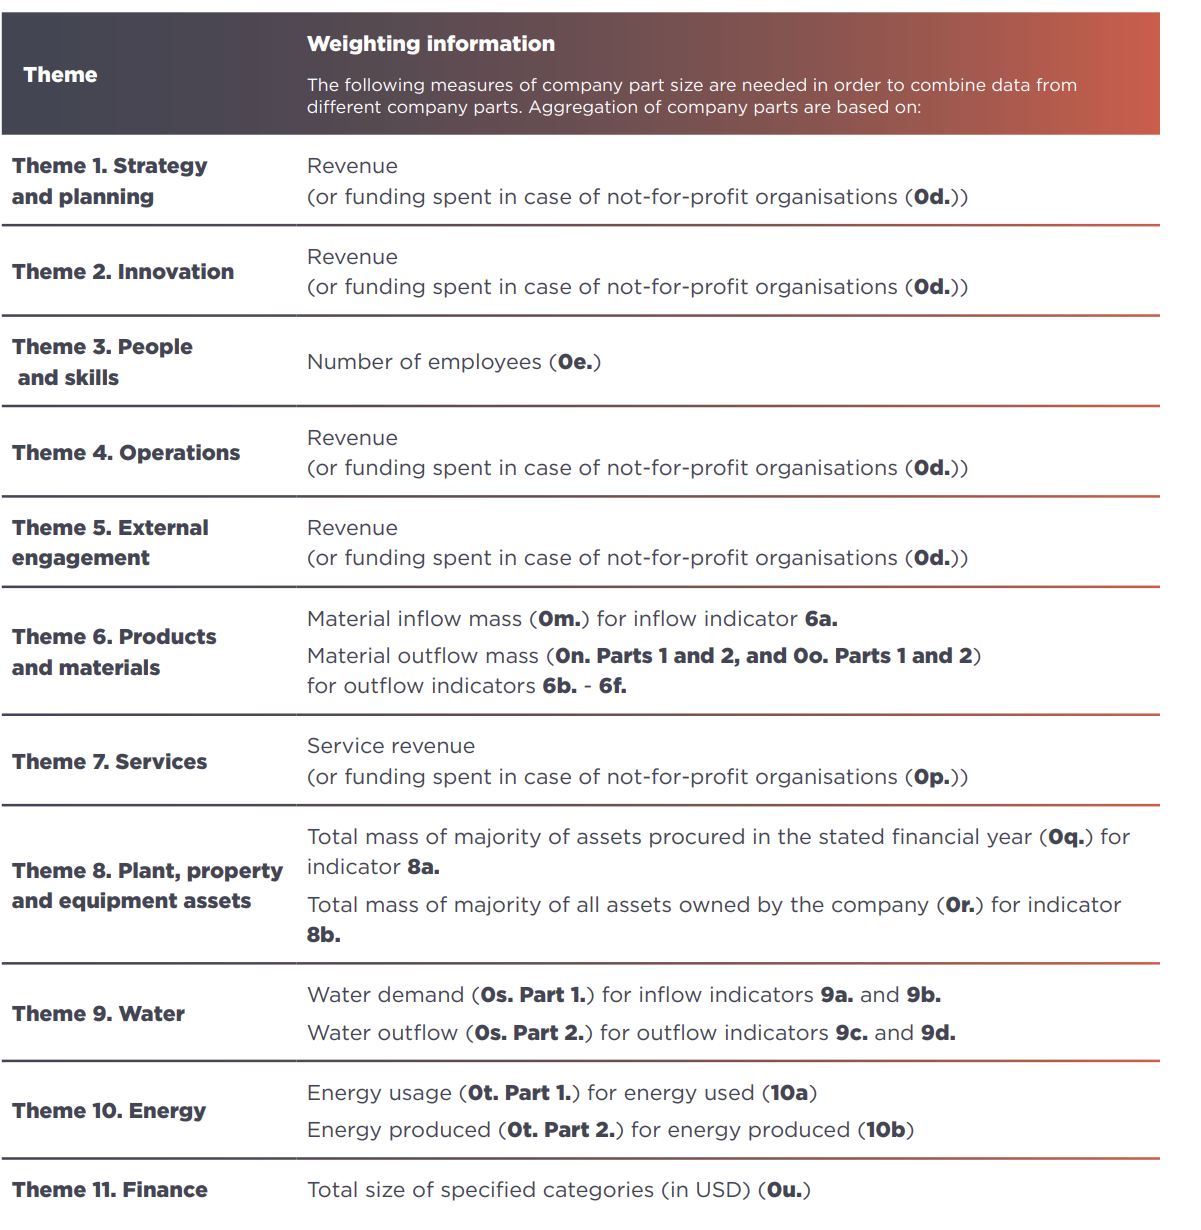

### Weighting information for Theme 6. Products and materials

In [6]:
M_in_description = w.Label(value='Please provide MIN, the total annual mass of all inflow products and materials (metric tonnes)')
M_in = w.FloatText(value=0.0)
M_In_container = w.VBox([M_in_description, M_in])

M_prod1_description = w.Label(value='Please provide the total annual outflow mass of products and materials that are designed to be consumed (e.g. food and feed) (metric tonnes). Subsequently referred to as MPROD1.')
M_prod1 = w.FloatText(value=0.0)
M_prod1_container = w.VBox([M_prod1_description, M_prod1])

M_prod2_description = w.Label(value='Please provide the total annual outflow mass of products and materials that are designed to be used (metric tonnes). Subsequently referred to as MPROD2.')
M_prod2 = w.FloatText(value=0.0)
M_prod2_container = w.VBox([M_prod2_description, M_prod2])

M_waste1_description = w.Label(value='Please provide the total annual outflow mass of materials processing waste and by-products that originate from products that are designed to be consumed (e.g. food waste) (metric tonnes). Subsequently referred to as MWASTE1.')
M_waste1 = w.FloatText(value=0.0)
M_waste1_container = w.VBox([M_waste1_description, M_waste1])

M_waste2_description = w.Label(value='Please provide the total annual outflow mass of materials processing waste and by-products that originate from products that are designed to be used (metric tonnes). Subsequently referred to as MWASTE2.')
M_waste2 = w.FloatText(value=0.0)
M_waste2_container = w.VBox([M_waste2_description, M_waste2])

mass_box = w.VBox([M_In_container, M_prod1_container, M_prod2_container, M_waste1_container, M_waste2_container])
mass_box

### Weighting information for Theme 7. Services

In [7]:
services_description = w.Label(value='Please provide the % share of total annual revenue that comes from your company’s services.')
services = w.FloatText(value=0.0)
services_container = w.VBox([services_description, services])
services_container

### Weighting information for Theme 8. Plant, Property and Equipment Assets

- You should include plant, property, and equipment assets used by your company operations (e.g. office buildings and IT equipment).
- You should exclude plant, property, and equipment assets owned by your business but used by customers (e.g. reusable pallets in a product-as-a-service business model), they are in scope of Theme 6 (Products and materials)

In [8]:
ui_8_procured

In [9]:
ui_8_procured

In [10]:
asset_selection_table_0q

In [11]:
ui_8_owned

### Weighting information for Theme 9. Water

- You should include water flows for operational processes (e.g. cooling water or water used in processes that are not incorporated into products and materials, like water used for dyeing).
- You should include water flows for operational processes (e.g. cooling water or water used in processes that are not incorporated into products and materials, like water used for dyeing).
- You should exclude material outflows that have water incorporated (e.g. beverages, processed foods, water content in wood), as they are in scope of Theme 6: Products and materials
- Please refer to the Water Guidelines in the Method Introduction Appendix for more detail on how to account for water in Circulytics.

In [12]:
water_demand_desc = w.Label(value='Please provide the total annual water demand (sourcing plus internal recirculation) volume (megalitres) for your company.')
water_demand = w.FloatText(value=0.0)
water_demand_container = w.VBox([water_demand_desc, water_demand])

water_outflow_desc = w.Label(value='Please provide the total annual water outflow volume (megalitres) for your company.')
water_outflow = w.FloatText(value=0.0)
water_outflow_container = w.VBox([water_outflow_desc, water_outflow])

water_box = w.VBox([water_demand_container, water_outflow_container])
water_box

### Weighting information for Theme 10. Energy

In [13]:
energy_use_desc = w.Label(value='What is the total annual energy usage (MWh) of your operations?')
energy_use = w.FloatText(value=0.0)
energy_use_container = w.VBox([energy_use_desc, energy_use])

energy_prod_desc = w.Label(value='What is the total annual energy production (MWh) of your company?')
energy_prod = w.FloatText(value=0.0)
energy_prod_container = w.VBox([energy_prod_desc, energy_prod])
energy_box = w.VBox([energy_use_container, energy_prod_container])
energy_box

### Weighting information for Theme 11. Finance

In [14]:
finance_weight_prompt = w.Label(value='What was the total size of each of the following categories at the end of the financial year stated at the beginning of the assessment (in USD)?')
lending = w.FloatText(value=0.0, description='Lending')
fixed_income = w.FloatText(value=0.0, description='Fixed income',style = {'description_width': 'initial'}, layout=w.Layout(width='300px'))
private_eq = w.FloatText(value=0.0, description='Private equity',style = {'description_width': 'initial'}, layout=w.Layout(width='300px'))
listed_eq = w.FloatText(value=0.0, description='Listed equity',style = {'description_width': 'initial'}, layout=w.Layout(width='300px'))
other_fin_1 = w.FloatText(value=0.0, description='Other (please specify)',style = {'description_width': 'initial'}, layout=w.Layout(width='300px'))
other_fin_2 = w.FloatText(value=0.0, description='Other (please specify)',style = {'description_width': 'initial'}, layout=w.Layout(width='300px'))
other_fin_3 = w.FloatText(value=0.0, description='Other (please specify)',style = {'description_width': 'initial'}, layout=w.Layout(width='300px'))
finance_weights = [lending, fixed_income, private_eq, listed_eq, other_fin_1, other_fin_2, other_fin_3]
finance_box = w.VBox([finance_weight_prompt,lending, fixed_income, private_eq, listed_eq, other_fin_1, other_fin_2, other_fin_3])
finance_box

# Build the UI interfaces to enter the indicators

In [20]:

theme_indicator_ui_boxes = {}
theme_indicator_widgets = {}
for theme_num, indicators in theme_indicators.items():
    theme_indicator_widgets[theme_num] = {}
    theme_items = []
    theme_items.append(w.HTML(f"<h1>Theme {theme_num}: {theme_names[theme_num]}</h1>"))
    theme_items.append(w.HTML(f"<h2>{theme_descriptions[theme_num]}</h2>"))
    for indicator, info in indicators.items():
        if info["type"] == "dropdown":
            container, widget = build_dropdown_block(indicator, info['prompt'], info['options'], info['scores'], subprompt = info.get('subprompt', None), bonus_checkbox=info.get('bonus_checkbox', None))
            theme_items.append(container)
            theme_indicator_widgets[theme_num][indicator] = widget
        elif info["type"] == "checkbox":
            container, widget = build_checkbox_block(indicator, info['prompt'], info['options'], subprompt = info.get('subprompt', None))
            theme_items.append(container)
            theme_indicator_widgets[theme_num][indicator] = widget
        elif info["type"] == "grouped_checkbox":
            container, widget = build_grouped_checkbox_block(indicator, info['prompt'], info['group labels'], info["group sublabels"], info["group options"], subprompt = info.get('subprompt', None))
            theme_items.append(container)
            theme_indicator_widgets[theme_num][indicator] = widget
        elif info["type"] == "both":
            container, widget = build_both_block(indicator, info['prompt'], info['dropdown_options'], info['dropdown_scores'], "Select all that apply:", info['checkbox_options'], subprompt = info.get('subprompt', None))
            theme_items.append(container)
            theme_indicator_widgets[theme_num][indicator] = widget
        elif info["type"] == "slider":
            container, widget = build_slider_block(indicator, info['prompt'], subprompt = info.get('subprompt', None))
            theme_items.append(container)
            theme_indicator_widgets[theme_num][indicator] = widget
        elif info["type"] == "sliders":
            if indicator == "6f":
                if "UP" in industry_type.value:
                    weights = info["weights_upstream"]
                else:
                    weights = info["weights_other"]
            elif theme_num == 11: # finance
                weights = [widget.value for widget in finance_weights]
            else:
                weights = info.get("weights", None)
            container, api = build_composite_slider_block(
                indicator,
                info['prompt'],
                info['items'],
                weights=weights,
                subprompt = info.get('subprompt', None)
            )
            theme_items.append(container)
            theme_indicator_widgets[theme_num][indicator] = api
        elif info["type"] == "multiple_dropdown":
            container, api = build_grouped_multiple_dropdown_block(
                indicator,
                info['prompt'],
                info['dropdown_descriptions'],
                info['dropdown_options'],
                info['dropdown_scores'],
                level_order=info.get('level_order', None),
                description_width=info.get('description_width', 'initial'),
                dropdown_width_px=info.get('dropdown_width_px', 360)
            )
            theme_items.append(container)
            theme_indicator_widgets[theme_num][indicator] = api
        elif info["type"] == "checkbox_table":
            if indicator == "8b":
                total_asset_mass_owned = sum([wid['mass_widget'].value for wid in asset_widgets_owned])
                if total_asset_mass_owned == 0:
                    owned_asset_weights = {wid['name']: 0.0 for wid in asset_widgets_owned}
                else:
                    owned_asset_weights = {wid['name']: wid['mass_widget'].value/total_asset_mass_owned for wid in asset_widgets_owned}
                cell_weights = {}
                for ri, row in enumerate(info['rows']):
                    for ci, col in enumerate(info['columns']):
                        cell_weights[(ri,ci)] = owned_asset_weights.get(row, 0.0)*info['col_scores'][ci]
                info['cell_scores'] = cell_weights
            container, api = build_checkbox_table_block(
                indicator,
                info['prompt'],
                info['rows'],
                column_labels=info.get('columns', []),
                column_descriptions=info.get('column_descriptions', None),
                per_col_scores=info.get('col_scores', None),
                per_cell_scores=info.get('cell_scores', None),
                description_width=info.get('description_width', 'initial'),
                cell_width_px=info.get('cell_width_px', 500)
            )
            theme_items.append(container)
            theme_indicator_widgets[theme_num][indicator] = api
        elif info['type'] == 'float':
            label = w.Label(value=info['prompt'])
            float_box = w.FloatText(value=0.0)
            container = w.VBox([label, float_box])
            theme_items.append(container)
            theme_indicator_widgets[theme_num][indicator] = float_box
        elif indicator == "8a":
            total_asset_mass_procured = sum([wid['mass_widget'].value for wid in asset_widgets_procured])
            if total_asset_mass_procured == 0:
                procured_asset_weights = {wid['name']: 0.0 for wid in asset_widgets_procured}
            else:
                procured_asset_weights = {wid['name']:wid['mass_widget'].value/total_asset_mass_procured for wid in asset_widgets_procured}

            container, api = build_percentage_table_block(
                indicator,
                info['prompt'],
                info['rows'],
                info['columns'],
                info['column_descriptions'],
                info['column_weights'],
                procured_asset_weights
            )
            theme_items.append(container)
            theme_indicator_widgets[theme_num][indicator] = api

    theme_box = w.VBox(theme_items)
    theme_indicator_ui_boxes[theme_num] = theme_box

# Circulytics Indicators

In [24]:
for tm in theme_names.keys():
    display(theme_indicator_ui_boxes[tm])

In [35]:
compute_btn = w.Button(description='Compute Circulytics score', button_style='success')
report_out = w.Output()

ui = w.VBox([compute_btn, report_out])

def compute_scores(_):
    report_out.clear_output()
    with report_out:
        company = {'industry_type':industry_type.value,'services_sold':services_sold.value,'material_flows':material_flows.value,'ownership':ownership.value,'water_intensive':water_intensive.value,'energy_producer':energy_producer.value}
        
        out_theme_w = compute_outcomes_theme_weights(company)
        masses = {'MIN':float(M_in.value),'MPROD1':float(M_prod1.value),'MPROD2':float(M_prod2.value),'MWASTE1':float(M_waste1.value),'MWASTE2':float(M_waste2.value)}
        masses['MALL'] = masses['MPROD1'] + masses['MPROD2'] + masses['MWASTE1'] + masses['MWASTE2']
        t6_w = theme6_indicator_weights(masses, theme_indicator_widgets)

        ind_scores = {tm: {} for tm in theme_indicators.keys()}
        theme_scores = {}
        for tm in ind_scores.keys():
            for ind in theme_indicators[tm]:
                if theme_indicators[tm][ind]['type'] == 'dropdown':
                    value = theme_indicator_widgets[tm][ind]['dropdown'].value
                    if 'bonus_checkbox' in theme_indicator_widgets[tm][ind]:
                        value += theme_indicator_widgets[tm][ind]['bonus_checkbox'].value
                    ind_scores[tm][ind] = clip_0_to_1(value)
                elif theme_indicators[tm][ind]['type'] == 'multiple_dropdown':
                    value = theme_indicator_widgets[tm][ind]["get_total_score"]()
                    ind_scores[tm][ind] = clip_0_to_1(value)
                elif theme_indicators[tm][ind]['type'] == 'checkbox':
                    ind_scores[tm][ind] = clip_0_to_1(sum([theme_indicators[tm][ind]['scores'][i] for i, cb in enumerate(theme_indicator_widgets[tm][ind]) if cb.value]))
                elif theme_indicators[tm][ind]['type'] == 'checkbox_table':
                    value = theme_indicator_widgets[tm][ind]['get_score']()
                    ind_scores[tm][ind] = clip_0_to_1(value)
                elif theme_indicators[tm][ind]['type'] == 'both':
                    dd_widget, cb_widgets = theme_indicator_widgets[tm][ind]
                    ind_scores[tm][ind] = clip_0_to_1(dd_widget.value + sum([theme_indicators[tm][ind]['checkbox_scores'][i] for i, cb in enumerate(cb_widgets) if cb.value]))
                elif theme_indicators[tm][ind]['type'] == 'slider':
                    ind_scores[tm][ind] = clip_0_to_1(theme_indicator_widgets[tm][ind].value/100.0)
                elif theme_indicators[tm][ind]['type'] == 'sliders':
                    api = theme_indicator_widgets[tm][ind]
                    ind_scores[tm][ind] = clip_0_to_1(api['get_weighted_score']()/100.0)
                elif theme_indicators[tm][ind]['type'] == 'float':
                    value = theme_indicator_widgets[tm][ind].value
                    if theme_indicators[tm][ind].get("percentage"):
                        value = value / 100.0
                    ind_scores[tm][ind] = clip_0_to_1(value)
                elif theme_indicators[tm][ind]['type'] == 'float_table':
                    api = theme_indicator_widgets[tm][ind]
                    value = api['get_overall_score']()
                    ind_scores[tm][ind] = clip_0_to_1(value)
                elif ind == "7a_part2":
                    # 7a part 2 does not have a score
                    continue
                else:
                    print(f"Unknown indicator type for {ind}")
            if tm == 5:
                theme_scores[tm] = weighted_average([(ind_scores[tm][ind], THEME_5_INDICATOR_WEIGHTS[ind]) for ind in ind_scores[tm]])
            elif tm in [1,2,3,4]:
                theme_scores[tm] = float(np.mean([ind_scores[tm][ind] for ind in ind_scores[tm]]))
            elif tm == 6:
                theme_scores[tm] = weighted_average([(ind_scores[tm][ind], t6_w[ind]) for ind in ind_scores[tm]])
            elif tm == 7:
                theme_scores[tm] = ind_scores[tm]['7a_part1']
            elif tm == 8:
                total_asset_mass_procured = sum([wid['mass_widget'].value for wid in asset_widgets_procured])
                total_asset_mass_owned = sum([wid['mass_widget'].value for wid in asset_widgets_owned])
                total_owned_plus_procured = total_asset_mass_owned + total_asset_mass_procured
                theme_scores[tm] = total_owned_plus_procured*theme_indicator_widgets[8]['8a']['get_overall_score']() + total_asset_mass_owned*theme_indicator_widgets[tm]['8b']['get_score']()
            elif tm == 9:
                t9_w = theme9_indicator_weights(float(water_demand.value), float(water_outflow.value))
                theme_scores[tm] = sum([ind_scores[tm][ind]*t9_w[ind] for ind in ind_scores[tm]])
            elif tm == 10:
                t10_w = theme10_indicator_weights(float(energy_use.value), float(energy_prod.value), energy_producer.value)
                theme_scores[tm] = sum([ind_scores[tm][ind]*t10_w[ind] for ind in ind_scores[tm]])
            elif tm == 11:
                theme_scores[tm] = np.mean([ind_scores[tm][ind] for ind in ind_scores[tm]])
        
        Enablers_score = weighted_average([(theme_scores[tm], ENABLER_THEME_WEIGHTS[tm]) for tm in [1,2,3,4,5]])
        Outcomes_score = weighted_average([(theme_scores[tm], out_theme_w[tm]) for tm in out_theme_w])
        Overall_equal = (Enablers_score + Outcomes_score) / 2.0
        Overall_score = Outcomes_score if Outcomes_score > Enablers_score else Overall_equal
        Overall_letter = to_letter_score(100*Overall_score)
        display(Markdown('### Results'))
        display(Markdown(f'Enablers score: {100*Enablers_score:.2f}%  '))
        display(Markdown(f'Outcomes score: {100*Outcomes_score:.2f}%  '))
        display(Markdown(f'Overall score: {100*Overall_score:.2f}% -> {Overall_letter}'))
        df_enab = pd.DataFrame({'Theme':[f"Theme {n}: {theme}" for n, theme in theme_names.items() if n in enablers],'Score %':[100*theme_scores[tm] for tm in enablers],'Weight %':[100*ENABLER_THEME_WEIGHTS[tm] for tm in enablers]})
        df_out = pd.DataFrame({'Theme':[f"Theme {n}: {theme}" for n, theme in theme_names.items() if n in outcomes],'Score %':[100*theme_scores[tm] for tm in outcomes],'Weight %':[100*out_theme_w[tm] for tm in outcomes]})
        display(Markdown('#### Enablers detail'))
        display(df_enab)
        display(Markdown('#### Outcomes detail (tailored weights)'))
        display(df_out)
        result = {'company':company,'enablers':{'scores':{tm: theme_scores[tm] for tm in enablers}},'outcomes':{'scores':{tm: theme_scores[tm] for tm in outcomes},'weights':out_theme_w},'category_scores':{'Enablers':Enablers_score,'Outcomes':Outcomes_score},'overall':{'score':Overall_score,'letter':Overall_letter}}
        with open('circulytics_result.json','w') as f: json.dump(result,f,indent=2)
        df_out.to_csv('circulytics_outcomes_detail.csv', index=False)
        df_enab.to_csv('circulytics_enablers_detail.csv', index=False)
        display(Markdown('Exports saved: circulytics_result.json, circulytics_outcomes_detail.csv, circulytics_enablers_detail.csv'))

compute_btn.on_click(compute_scores)
ui
